# imports 

In [87]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from collections import Counter
import re

from sklearn.model_selection import train_test_split ,GridSearchCV ,RandomizedSearchCV,StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score , classification_report,confusion_matrix
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import cross_val_score,cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

# reading and cleaning and  EDA

In [2]:
df=pd.read_csv("archive (14)/IMDB Dataset.csv")
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


In [3]:
df["review"][0]

"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fa

In [4]:
df["sentiment"].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [6]:
df.isna().sum()

review       0
sentiment    0
dtype: int64

## duplicated rows

In [7]:
df.duplicated().sum()

np.int64(418)

In [8]:
df["review"].value_counts().head(10)

review
Loved today's show!!! It was a variety and not solely cooking (which would have been great too). Very stimulating and captivating, always keeping the viewer peeking around the corner to see what was coming up next. She is as down to earth and as personable as you get, like one of us which made the show all the more enjoyable. Special guests, who are friends as well made for a nice surprise too. Loved the 'first' theme and that the audience was invited to play along too. I must admit I was shocked to see her come in under her time limits on a few things, but she did it and by golly I'll be writing those recipes down. Saving time in the kitchen means more time with family. Those who haven't tuned in yet, find out what channel and the time, I assure you that you won't be disappointed.                                                                                                                                                                                                         

In [9]:
df[df["review"].duplicated(keep=False)].groupby("review")["sentiment"].nunique().value_counts()

sentiment
1    406
Name: count, dtype: int64

In [10]:
df.duplicated(subset=["review"]).sum()

np.int64(418)

In [11]:
df.drop_duplicates(subset=["review"], inplace=True)

In [12]:
df.shape

(49582, 2)

In [13]:
df.duplicated(subset=["review"]).sum()

np.int64(0)

## word count 

In [14]:
df.groupby("sentiment")["review"].nunique()

sentiment
negative    24698
positive    24884
Name: review, dtype: int64

In [15]:
df["word_count"] = df["review"].apply(
    lambda x: len(x.split())
)

In [16]:
df["word_count"].mean()

np.float64(231.35016739945948)

In [17]:
df["word_count"].describe()

count    49582.000000
mean       231.350167
std        171.542020
min          4.000000
25%        126.000000
50%        173.000000
75%        281.000000
max       2470.000000
Name: word_count, dtype: float64

In [18]:
df.groupby("sentiment")["word_count"].describe()

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,24698.0,229.596607,165.103430,4.0,128.0,174.0,278.0,1522.0
positive,24884.0,233.090620,177.688169,10.0,125.0,172.0,284.0,2470.0


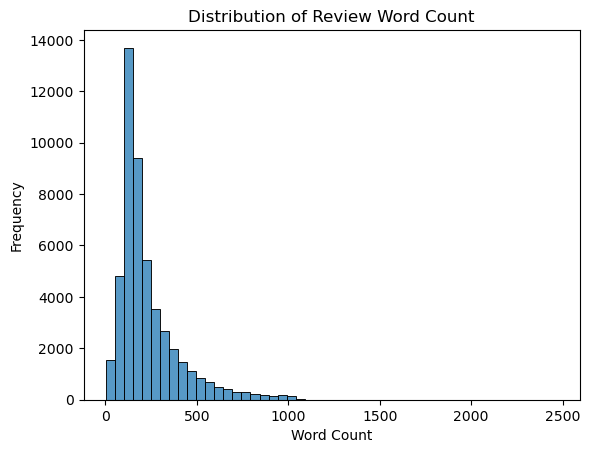

In [19]:
sns.histplot(df["word_count"], bins=50)
plt.title("Distribution of Review Word Count")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.show()

In [20]:
(df["word_count"] <= 500).mean() * 100

np.float64(92.16852890161752)

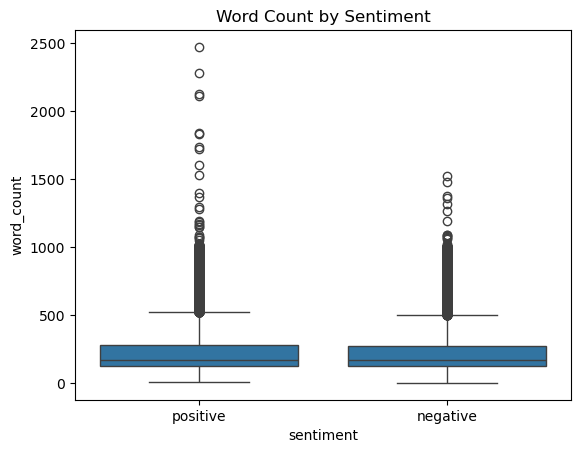

In [21]:
sns.boxplot(data=df, x="sentiment", y="word_count")
plt.title("Word Count by Sentiment")
plt.show()

## removing the html tags 

In [22]:
df["review"] = df["review"].str.replace(
    r"<br\s*/?>", " ", regex=True
)

In [23]:
df["review"][199]

"The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by Seagal's driving, but that probably would have ended the whole premise for the movie.  It seems like they decided to make all kinds of changes in the movie plot, so just plan to enjoy the action, and do not expect a coherent plot. Turn any sense of logic you may have, it will reduce your chance of getting a headache.  I does give me some hope that Steven Seagal is trying to move back towards the type of characters he portrayed in his more popular movies."

In [24]:
df["review"].str.contains(r"<[^>]+>", regex=True).sum()

np.int64(16)

In [25]:
tags = Counter(
    tag.lower()
    for review in df["review"]
    for tag in re.findall(r"<[^>]+>", review)
)

tags

Counter({'<i>': 8,
         '</i>': 8,
         '<grin>': 2,
         '< cough >': 2,
         '<p>': 1,
         '< yes >': 1,
         '<<<<  >': 1,
         '<< review posted at filmdailies.com>': 1,
         '<spoiler>': 1,
         '</spoiler>': 1,
         '< cough , cough >': 1,
         '<hr>': 1,
         '<http://rogerebert.suntimes.com/apps/pbcs.dll/section?category=answerman>': 1,
         '<sp?) classic "romeo & juliet". guess i\'ll have to rent that next.  >': 1,
         '<..>': 1,
         '<<<sigh>': 1,
         '<em>': 1,
         '</em>': 1,
         '<-----minor spoilers!----->': 1,
         '<-----minor spoilers!---->': 1})

In [26]:
df[df["review"].str.contains(
    r"<grin>|< cough|< yes|<spoiler>|<<<<|<-----",
    case=False,
    regex=True
)]["review"].head(5)

1513     This all-but-ignored masterpiece is about the ...
3871     I'm a sucker for a decent superhero movie. (I'...
13736    >>> Great News there is a BBC DVD release sche...
25373    >>>>>>>>>>>>> >>>>>>>>>>>>>>>>> >>>>>>>>>>>>>>...
25952    Contains spoilers  "Hollow Man" is probably th...
Name: review, dtype: object

In [27]:
df["clean_review"] = df["review"].str.replace(
    r"<br\s*/?>", " ", regex=True
)

In [28]:
df

,review,sentiment,word_count,clean_review
0,One of the other reviewers has mentioned that ...,positive,307,One of the other reviewers has mentioned that ...
1,A wonderful little production. The filming t...,positive,162,A wonderful little production. The filming t...
2,I thought this was a wonderful way to spend ti...,positive,166,I thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,138,Basically there's a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,230,"Petter Mattei's ""Love in the Time of Money"" is..."
...,...,...,...,...
49995,I thought this movie did a down right good job...,positive,194,I thought this movie did a down right good job...
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative,112,"Bad plot, bad dialogue, bad acting, idiotic di..."
49997,I am a Catholic taught in parochial elementary...,negative,230,I am a Catholic taught in parochial elementary...
49998,I'm going to have to disagree with the previou...,negative,212,I'm going to have to disagree with the previou...


In [29]:
df["word_count"]=df["clean_review"].apply(
    lambda x: len(x.split())
)

In [30]:
df["word_count"].mean()

np.float64(229.0596385785164)

In [31]:
df["clean_review"] = df["clean_review"].str.lower()

In [32]:
df["clean_review"] = df["clean_review"].str.replace(
    r"https?://\S+|www\.\S+", " ", regex=True
)

In [33]:
df["clean_review"] = df["clean_review"].str.replace(
    r"\s+", " ", regex=True
).str.strip()

In [34]:
pd.set_option("display.max_colwidth", None)

In [35]:
df[["review", "clean_review"]].sample(1, random_state=13)

,review,clean_review
8502,"What a travesty of movie ratings injustice - a 2.1 on the IMDb scale as I write this. Folks, this is a lot closer to a 3.0, I'll even go out on a limb and say 4.0 where I've put it. Come on - how can you have a movie about a net of static electricity surrounding the earth and alien amorphic cell structures, and not give it at least a 4.0 for creativity? Then you've got all that great dialog like - ""Dave, look at the composition of this mud."" You know, I don't think they ever got back to that mud. No matter, this is the kind of flick that 'Z' movie diehards live for, and I can now rest easy. Actually, I saw this quite a few years ago without the proper appreciation for it, along with Corman titles like ""Attack of the Giant Leeches "" and ""The Wasp Woman"". I don't know what the fascination might be, but to quote a character from the film - ""Whatever it is, it works fast!"" Back to that alien amorphic cell structure - I liked the idea of a third element competing against your standard red and white blood cells. When astronaut John Corcoran (Michael Emmet) returned from the dead, I had visions of a scene that might have been a precursor to 1979's ""Alien"", but that was not to be. Instead, budget restrictions limit the picture to a de-feathered Big Bird knock off, even though that concept was still almost a decade away. Who knows where one idea leaves off and picks up with another? Look, this is not that bad. Not that good, but not that bad. Anytime you can hook up crash landing astronauts with alien beings committed to taking over the Earth, you've got a winning combination. Throw in the cheesy monster factor and you're on your way. Just remember - ""A wounded animal that large isn't good"".","what a travesty of movie ratings injustice - a 2.1 on the imdb scale as i write this. folks, this is a lot closer to a 3.0, i'll even go out on a limb and say 4.0 where i've put it. come on - how can you have a movie about a net of static electricity surrounding the earth and alien amorphic cell structures, and not give it at least a 4.0 for creativity? then you've got all that great dialog like - ""dave, look at the composition of this mud."" you know, i don't think they ever got back to that mud. no matter, this is the kind of flick that 'z' movie diehards live for, and i can now rest easy. actually, i saw this quite a few years ago without the proper appreciation for it, along with corman titles like ""attack of the giant leeches "" and ""the wasp woman"". i don't know what the fascination might be, but to quote a character from the film - ""whatever it is, it works fast!"" back to that alien amorphic cell structure - i liked the idea of a third element competing against your standard red and white blood cells. when astronaut john corcoran (michael emmet) returned from the dead, i had visions of a scene that might have been a precursor to 1979's ""alien"", but that was not to be. instead, budget restrictions limit the picture to a de-feathered big bird knock off, even though that concept was still almost a decade away. who knows where one idea leaves off and picks up with another? look, this is not that bad. not that good, but not that bad. anytime you can hook up crash landing astronauts with alien beings committed to taking over the earth, you've got a winning combination. throw in the cheesy monster factor and you're on your way. just remember - ""a wounded animal that large isn't good""."


In [36]:
(df["clean_review"].str.strip() == "").sum()

np.int64(0)

# spliting

In [37]:
df["sentiment"] = df["sentiment"].map({
    "positive": 1,
    "negative": 0
})

In [38]:
x=df["clean_review"]
y=df["sentiment"]

In [39]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=13,stratify=y)

In [40]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("nb", MultinomialNB())
])

In [41]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=13
)

In [42]:
results = cross_validate(
    pipeline,
    x_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "f1_macro"]
)

print("Mean Accuracy:", results["test_accuracy"].mean())
print("Mean F1 Macro:", results["test_f1_macro"].mean())

Mean Accuracy: 0.8629018025967478
Mean F1 Macro: 0.8628521919882971


In [43]:
tfidf = TfidfVectorizer(min_df=3,ngram_range=(1,3),sublinear_tf=True,max_df=0.9)

X_train_tfidf = tfidf.fit_transform(x_train)
X_test_tfidf = tfidf.transform(x_test)

# Model Trainig

In [44]:
nb = MultinomialNB(alpha=1,fit_prior=False)
nb.fit(X_train_tfidf, y_train)

,alpha,1
,force_alpha,True
,fit_prior,False
,class_prior,None


In [45]:
Y_pred=nb.predict(X_test_tfidf)

In [46]:
nb.score(X_train_tfidf,y_train)

0.9546955754443464

In [47]:
accuracy_score(Y_pred,y_test)

0.8979530099828578

In [48]:
print(classification_report(y_test,Y_pred))

              precision    recall  f1-score   support

           0       0.90      0.90      0.90      4940
           1       0.90      0.90      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



In [49]:
confusion_matrix(y_test,Y_pred)

array([[4449,  491],
       [ 521, 4456]])

# Model Comparison (MultinomialNB / Logistic Regression / SVM)

In [50]:
# LogisticRegression

In [51]:
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_tfidf, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [52]:
lr_pred = lr.predict(X_test_tfidf)

In [53]:
lr.score(X_train_tfidf, y_train)

0.9592335812429094

In [54]:
accuracy_score(y_test, lr_pred)

0.9073308460219824

In [55]:
print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.92      0.89      0.91      4940
           1       0.90      0.92      0.91      4977

    accuracy                           0.91      9917
   macro avg       0.91      0.91      0.91      9917
weighted avg       0.91      0.91      0.91      9917



In [56]:
# LinearSVC

In [57]:
svm = LinearSVC(C=1, random_state=42)

In [58]:
svm.fit(X_train_tfidf, y_train)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,verbose,0
,random_state,42


In [59]:
svm_pred = svm.predict(X_test_tfidf)

In [60]:
svm.score(X_train_tfidf, y_train)

0.9999243665700239

In [61]:
accuracy_score(y_test, svm_pred)

0.9202379751941111

In [62]:
# overfittingggg

In [63]:
print(classification_report(y_test, svm_pred))

              precision    recall  f1-score   support

           0       0.93      0.91      0.92      4940
           1       0.91      0.93      0.92      4977

    accuracy                           0.92      9917
   macro avg       0.92      0.92      0.92      9917
weighted avg       0.92      0.92      0.92      9917



In [64]:
param_grid = {
    "C": [0.001, 0.01, 0.1, 1]
}

grid = GridSearchCV(
    LinearSVC(random_state=42),
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

In [65]:
grid.fit(X_train_tfidf, y_train)

Fitting 5 folds for each of 4 candidates, totalling 20 fits


,estimator,LinearSVC(random_state=42)
,param_grid,"{'C': [0.001, 0.01, ...]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [66]:
best_svm = grid.best_estimator_

svm_pred = best_svm.predict(X_test_tfidf)

print("Test Accuracy:", accuracy_score(y_test, svm_pred))
print(classification_report(y_test, svm_pred))

Test Accuracy: 0.9202379751941111
              precision    recall  f1-score   support

           0       0.93      0.91      0.92      4940
           1       0.91      0.93      0.92      4977

    accuracy                           0.92      9917
   macro avg       0.92      0.92      0.92      9917
weighted avg       0.92      0.92      0.92      9917



In [67]:
print("Best C:", grid.best_params_)
print("Train Accuracy:", best_svm.score(X_train_tfidf, y_train))
print("Test Accuracy:", accuracy_score(y_test, svm_pred))
print("CV F1:", grid.best_score_)

Best C: {'C': 1}
Train Accuracy: 0.9999243665700239
Test Accuracy: 0.9202379751941111
CV F1: 0.9164358137068367


In [68]:
review ="notvery good"

review_tfidf = tfidf.transform([review])

prediction = lr.predict(review_tfidf)

if prediction[0] == 1:
    print("Positive Review 😊")
else:
    print("Negative Review 😞")

Positive Review 😊


# Stacking Classifier.

In [69]:
estimators = [
    ("nb", MultinomialNB()),
    ("lr", LogisticRegression(max_iter=1000)),
    ("svm", LinearSVC(C=1.0, random_state=42))
]

In [70]:
stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
    n_jobs=-1
)

In [71]:
stacking.fit(X_train_tfidf, y_train)

,estimators,"[('nb', ...), ('lr', ...), ...]"
,final_estimator,LogisticRegre...max_iter=1000)
,cv,5
,stack_method,'auto'
,n_jobs,-1
,passthrough,False
,verbose,0
,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [72]:
stack_pred = stacking.predict(X_test_tfidf)

In [73]:
print("Stacking Accuracy:", accuracy_score(y_test, stack_pred))

Stacking Accuracy: 0.9242714530604014


In [74]:
print(classification_report(y_test, stack_pred))

              precision    recall  f1-score   support

           0       0.93      0.92      0.92      4940
           1       0.92      0.93      0.93      4977

    accuracy                           0.92      9917
   macro avg       0.92      0.92      0.92      9917
weighted avg       0.92      0.92      0.92      9917



In [75]:
stack_train_pred = stacking.predict(X_train_tfidf)

print("Train Accuracy:",
      accuracy_score(y_train, stack_train_pred))

print("Test Accuracy:",
      accuracy_score(y_test, stack_pred))

Train Accuracy: 0.9999495777133492
Test Accuracy: 0.9242714530604014


In [76]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Naive Bayes": nb,
    "Logistic Regression": lr,
    "Linear SVM": best_svm,
    "Stacking": stacking
}

results = []

for name, model in models.items():
    pred = model.predict(X_test_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred)
    })

comparison = pd.DataFrame(results)
comparison.sort_values("F1-score", ascending=False, inplace=True)

comparison

,Model,Accuracy,Precision,Recall,F1-score
3,Stacking,0.924271,0.918914,0.931284,0.925057
2,Linear SVM,0.920238,0.913964,0.928471,0.921160
1,Logistic Regression,0.907331,0.897687,0.920233,0.908820
0,Naive Bayes,0.897953,0.900748,0.895318,0.898025


#  error handling 

In [77]:
NEG_WORDS = {"not", "no", "never", "none", "nobody", "nothing", "neither",
             "nor", "cannot", "hardly", "barely", "without"}

In [78]:
def mark_negation(text: str, window: int = 3) -> str:
    """'not very good' -> 'not NOT_very NOT_good' (until the next punctuation mark)."""
    tokens = re.findall(r"[a-z']+|[.,;:!?]", text.lower())
    out, left = [], 0
    for t in tokens:
        if t in ".,;:!?":
            left = 0
            continue
        if t in NEG_WORDS or t.endswith("n't"):
            out.append(t)
            left = window
        elif left > 0:
            out.append("NOT_" + t)
            left -= 1
        else:
            out.append(t)
    return " ".join(out)

In [79]:
print(mark_negation("this movie was not very good, but the acting wasn't bad"))

this movie was not NOT_very NOT_good but the acting wasn't NOT_bad


In [80]:
neg_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(preprocessor=mark_negation,
                              token_pattern=r"[A-Za-z_']+",
                              sublinear_tf=True, ngram_range=(1, 3),
                              min_df=3, max_df=0.9)),  
    ("svm", LinearSVC(C=1, random_state=42)),
])

In [81]:
neg_pipe.fit(x_train, y_train)

,steps,"[('tfidf', ...), ('svm', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,<function mar...002138E0B4CC0>
,tokenizer,None


In [82]:
neg_pred = neg_pipe.predict(x_test)

In [83]:
neg_pipe.score(x_train, y_train)

0.9999243665700239

In [84]:
accuracy_score(y_test, neg_pred)

0.924573963900373

In [85]:
print(classification_report(y_test, neg_pred))

              precision    recall  f1-score   support

           0       0.93      0.92      0.92      4940
           1       0.92      0.93      0.93      4977

    accuracy                           0.92      9917
   macro avg       0.92      0.92      0.92      9917
weighted avg       0.92      0.92      0.92      9917



In [86]:
tests = ["not very good", "not good at all", "wasn't bad at all", "I didn't hate it",
         "not worth the money", "never boring", "absolutely loved it", "waste of time","not a waste of time"]

lab = {1: "Positive", 0: "Negative"}
pd.DataFrame({
    "text": tests,
    "old (lr)":   [lab[lr.predict(tfidf.transform([t]))[0]] for t in tests],
    "new (neg)":  [lab[p] for p in neg_pipe.predict(tests)],
})

,text,old (lr),new (neg)
0,not very good,Positive,Negative
1,not good at all,Negative,Negative
2,wasn't bad at all,Negative,Negative
3,I didn't hate it,Negative,Negative
4,not worth the money,Negative,Negative
5,never boring,Negative,Positive
6,absolutely loved it,Positive,Positive
7,waste of time,Negative,Negative
8,not a waste of time,Negative,Negative


# xgboost

In [89]:
xgb = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.3,
    max_bin=64,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=13,
    n_jobs=2,
    tree_method="hist"
)

xgb.fit(X_train_tfidf, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.3
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [90]:
xgb_pred = xgb.predict(X_test_tfidf)

print("Train Accuracy:", xgb.score(X_train_tfidf, y_train))
print("Test Accuracy:", accuracy_score(y_test, xgb_pred))

print(classification_report(y_test, xgb_pred))

Train Accuracy: 0.8227152401361402
Test Accuracy: 0.8120399314308763
              precision    recall  f1-score   support

           0       0.84      0.76      0.80      4940
           1       0.79      0.86      0.82      4977

    accuracy                           0.81      9917
   macro avg       0.81      0.81      0.81      9917
weighted avg       0.81      0.81      0.81      9917



# final comparisson

In [92]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

predictions = {
    "Naive Bayes": nb.predict(X_test_tfidf),
    "Logistic Regression": lr.predict(X_test_tfidf),
    "Linear SVM": best_svm.predict(X_test_tfidf),
    "Stacking": stacking.predict(X_test_tfidf),
    "Negation SVM": neg_pipe.predict(x_test)
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="binary"),
        "Recall": recall_score(y_test, pred, average="binary"),
        "F1-score": f1_score(y_test, pred, average="binary")
    })

comparison = pd.DataFrame(results)
comparison = comparison.sort_values("F1-score", ascending=False)

comparison

,Model,Accuracy,Precision,Recall,F1-score
4,Negation SVM,0.924574,0.918796,0.932088,0.925394
3,Stacking,0.924271,0.918914,0.931284,0.925057
2,Linear SVM,0.920238,0.913964,0.928471,0.921160
1,Logistic Regression,0.907331,0.897687,0.920233,0.908820
0,Naive Bayes,0.897953,0.900748,0.895318,0.898025


# Model Saving

# GUI 

# LINK 